# Visualização de Dados: Matplotlib e Seaborn

## 1. Por que visualizar?

Para um engenheiro, a visualização é a ferramenta definitiva para:
1. **Identificar Outliers**: Um sensor falhando pode gerar um valor absurdo que é fácil de ver em um gráfico, mas difícil de achar em uma tabela de 1 milhão de linhas.
2. **Entender Distribuições**: As peças que fabricamos estão dentro da tolerância? O gráfico de sino (Normal) nos dirá.
3. **Comunicação**: Decisores (gerentes, clientes) entendem gráficos, não códigos.

### O Ecossistema Python:
*   **Matplotlib**: É a base da visualização de dados. Dá controle total, mas exige mais linhas de código e maior conhecimento da biblioteca para entender perfeitamente o que está sendo feito.
*   **Seaborn**: É construída sobre o Matplotlib. Ela já vem com "estilos" prontos e entende o Pandas perfeitamente. Pense nela como uma biblioteca mais morderna, ela abstrai grande parte do Matplotlib para que seja mais fácil e intuitivo a construção dos gráficos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Comando para garantir que os gráficos apareçam dentro do notebook
%matplotlib inline

# Definindo o tema visual padrão do Seaborn
sns.set_theme(style="darkgrid")

## 2. Anatomia de um Gráfico (Matplotlib)

No Matplotlib, trabalhamos com camadas:
1.  **Figure**: É a folha de papel (o espaço total).
2.  **Axes**: É o gráfico em si (com eixos x e y).
3.  **Labels**: Títulos e nomes dos eixos.

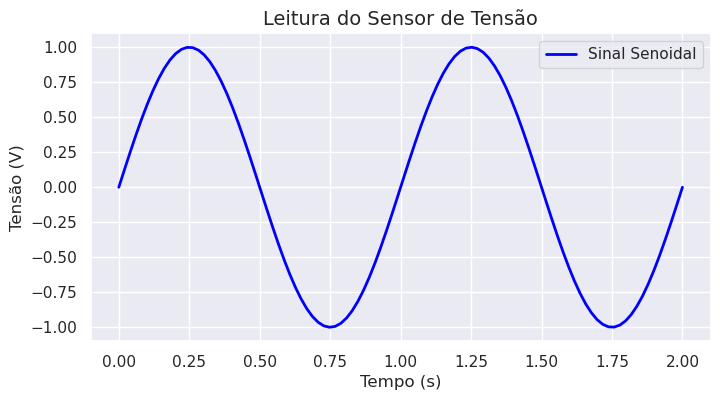

In [2]:
# Criando dados fictícios de um sensor
tempo = np.linspace(0, 2, 100)
tensao = np.sin(2 * np.pi * tempo)

plt.figure(figsize=(8, 4)) # Define o tamanho da "folha"
plt.plot(tempo, tensao, label='Sinal Senoidal', color='blue', linewidth=2)

# Adicionando os detalhes essenciais para qualquer engenheiro
plt.title('Leitura do Sensor de Tensão', fontsize=14)
plt.xlabel('Tempo (s)')
plt.ylabel('Tensão (V)')
plt.legend() # Mostra a legenda definida no 'label' do plot
plt.grid(True)

plt.show()

## 3. A Mágica do Seaborn

O Seaborn é focado em **Dados Tabulares** (Pandas). Ele permite criar gráficos complexos com apenas uma linha.

Vamos carregar o Titanic para ver isso na prática.

In [3]:
df = pd.read_csv('titanic.csv')
df['age'] = pd.to_numeric(df['age'], errors='coerce')
df['fare'] = pd.to_numeric(df['fare'], errors='coerce')

### Gráficos de Distribuição (Histogramas)
O `histplot` mostra onde a maioria dos dados está concentrada. O parâmetro `kde=True` adiciona uma linha de suavização que ajuda a ver a "forma" da distribuição.

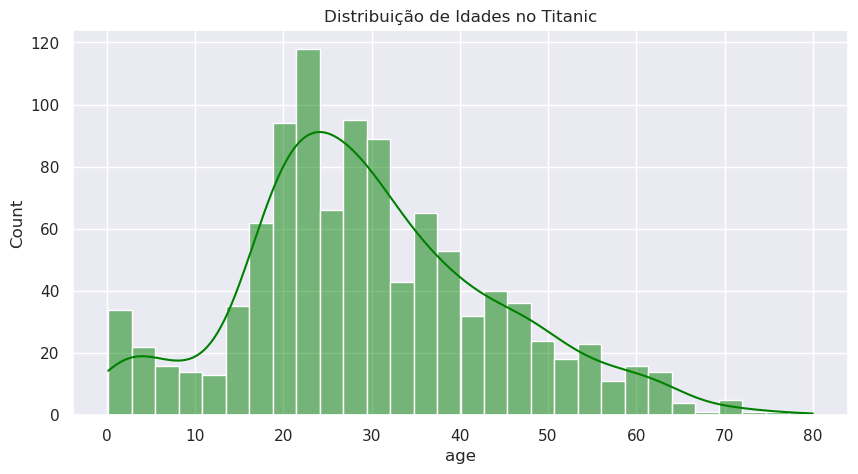

In [4]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='age', kde=True, color='green', bins=30)
plt.title('Distribuição de Idades no Titanic')
plt.show()

### Comparando Categorias (Boxplot)
O **Boxplot** é vital. Ele mostra:
*   A linha central: Mediana.
*   A caixa: Onde estão 50% dos dados.
*   Pontos isolados: **Outliers** (valores discrepantes).

Vamos ver se pessoas de classes mais altas pagavam muito mais caro:

/tmp/ipykernel_47555/1862454646.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='pclass', y='fare', palette='Set1')


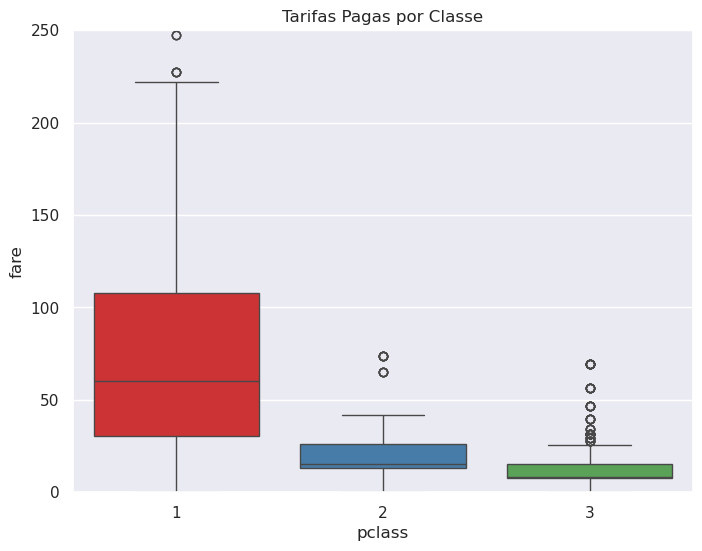

In [5]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='pclass', y='fare', palette='Set1')
plt.ylim(0, 250) # Cortamos o topo para ver melhor as caixas
plt.title('Tarifas Pagas por Classe')
plt.show()

### O Parâmetro `hue` (A Terceira Dimensão)
O `hue` permite separar os dados por uma categoria usando cores. É uma das funções mais poderosas do Seaborn.

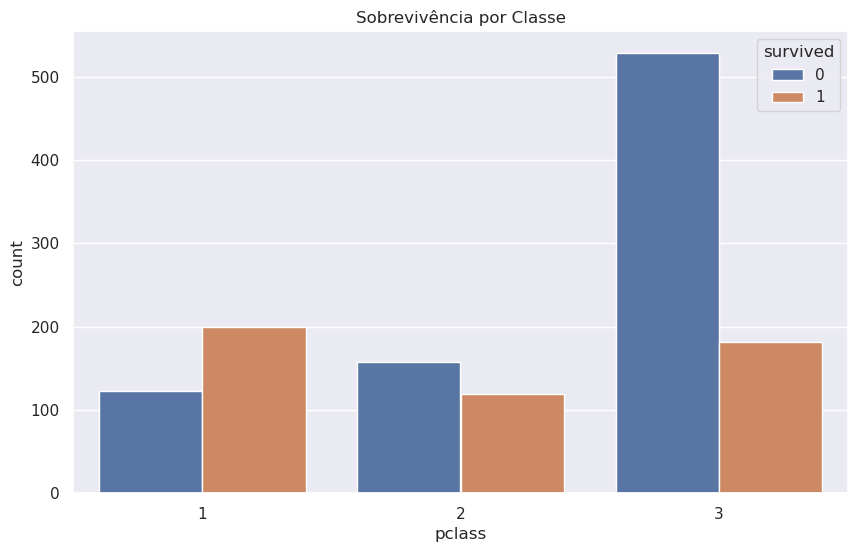

In [6]:
plt.figure(figsize=(10, 6))
# x=Classe, hue=Sobreviveu? (0 ou 1)
sns.countplot(data=df, x='pclass', hue='survived')
plt.title('Sobrevivência por Classe')
plt.show()

## Resumo de Escolha de Gráficos

| Objetivo | Gráfico Recomendado |
| :--- | :--- |
| Ver tendência ao longo do tempo | `plt.plot()` ou `sns.lineplot()` |
| Ver a forma da distribuição (frequência) | `sns.histplot()` |
| Comparar estatísticas (mediana, outliers) | `sns.boxplot()` |
| Ver relação entre duas variáveis numéricas | `sns.scatterplot()` |
| Contar ocorrências de categorias | `sns.countplot()` |

## Conclusão Final

Agora você completou sua caixa de ferramentas básica para lidar diretamente com o aprendizado de máquina e redes neurais artificiais:
1.  **Pandas**: Para carregar e limpar.
2.  **NumPy**: Para calcular.
3.  **Matplotlib/Seaborn**: Para visualizar.

Com essas três bibliotecas, você está pronto para qualquer desafio de engenharia que envolva dados. O próximo passo é aplicar esses conhecimentos em problemas reais de **Aprendizado de Máquina**!